# FitAI System Evaluation v3 — BGE-M3 Multilingual Intent Router & Live System Audit

Notebook **v3** đánh giá toàn diện hệ thống FitAI sau khi nâng cấp bộ phân loại ý định sang **`BAAI/bge-m3` (đóng băng, CLS pooling + chuẩn hoá L2) + Softmax Logistic Regression** (giữ fallback TF-IDF) và đối chiếu trực tiếp với baseline **v2 (TF-IDF)**:

1. **System State, Database Coverage & Full Pytest Audit** (`VN2007`, `ADMIN_MANUAL`, `USDA_SR_LEGACY_2018`, `ChromaDB RAG`, `WorkoutLog`)
2. **Intent Classifier v3 (`BAAI/bge-m3`) vs Baseline v2 (`TF-IDF`)** — 52 câu held-out song ngữ Việt–Anh, Macro-F1, OOS Guardrail TPR/FPR & các câu đã khắc phục
3. **Data & Math Plausibility Audit** — Hồi quy `300g tôm hùm`, Atwater (`4P + 9F + 4C`), ngưỡng OPUS-MT (`0.55`), `BMI/BMR/TDEE` & `WorkoutLog` tuần
4. **End-to-End Chatbot Response & Grounding (`test respond`)** — Đo độ trễ thực tế, tool calling, số liệu & trích dẫn nguồn trên Fast-Path + Live Gemini 2.5 Flash Agent

In [1]:
import asyncio
import json
import os
import sys
import time
import urllib.request
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sqlalchemy import func, select

CWD = Path.cwd().resolve()
BACKEND_DIR = CWD.parent if CWD.name == "evaluation_v3" else (CWD / "backend" if (CWD / "backend").is_dir() else CWD)
REPO_ROOT = BACKEND_DIR.parent
EVAL_V3_DIR = BACKEND_DIR / "evaluation_v3"
EVAL_V2_DIR = BACKEND_DIR / "evaluation_v2"
CHARTS_DIR = EVAL_V3_DIR / "charts"
RESULTS_DIR = EVAL_V3_DIR / "results"
CHARTS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

os.chdir(BACKEND_DIR)
if str(BACKEND_DIR) not in sys.path:
    sys.path.insert(0, str(BACKEND_DIR))

from dotenv import load_dotenv
load_dotenv(BACKEND_DIR / ".env")

from core.config import settings
if (REPO_ROOT / "data" / "knowledge").is_dir():
    settings.KNOWLEDGE_DIR = str(REPO_ROOT / "data" / "knowledge")
if not os.path.exists("/.dockerenv") and settings.CHROMA_HOST == "localhost" and settings.CHROMA_PORT == 8000:
    settings.CHROMA_PORT = 8001

plt.rcParams.update({
    "figure.dpi": 130,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})
print(f"Backend root : {BACKEND_DIR}")
print(f"Eval v3 out  : {EVAL_V3_DIR}")
print(f"Intent model : {settings.INTENT_EMBEDDING_MODEL} (enabled={settings.INTENT_EMBEDDING_ENABLED})")
print(f"Gemini model : {settings.GEMINI_MODEL} | API key set: {bool(settings.GOOGLE_API_KEY)}")

Backend root : /Users/haidongnguyen/Google Drive Universal/fitai/backend
Eval v3 out  : /Users/haidongnguyen/Google Drive Universal/fitai/backend/evaluation_v3
Intent model : BAAI/bge-m3 (enabled=True)
Gemini model : gemini-2.5-flash | API key set: True


## 1. System Runtime Health, Data Inventory & Full Pytest Summary
Kiểm tra trạng thái Backend FastAPI, ChromaDB RAG, Neon Cloud PostgreSQL và kết quả kiểm thử `pytest`.

Backend /health : {'status': 'ok', 'version': '1.0.0'}
ChromaDB chunks : 134
Foods in Neon DB: VN2007=509, ADMIN_MANUAL=70, USDA=7793 -> TOTAL=8372
WorkoutLog rows : 1
Pytest v3 audit : {'headline': 'Docker BGE-M3 + Chat/AI Suites 100% Green (107/107 post-fix)', 'suites': [{'name': 'Docker Full Baseline (pre-ChatAPI fix: 2 failed)', 'passed': 1018}, {'name': 'Docker Post-Fix AI/Chat/Intent/Health', 'passed': 107}, {'name': 'Intent Classifier BGE-M3 + TF-IDF Fallback', 'passed': 35}, {'name': 'Chat API Integration (post-fix)', 'passed': 14}]}


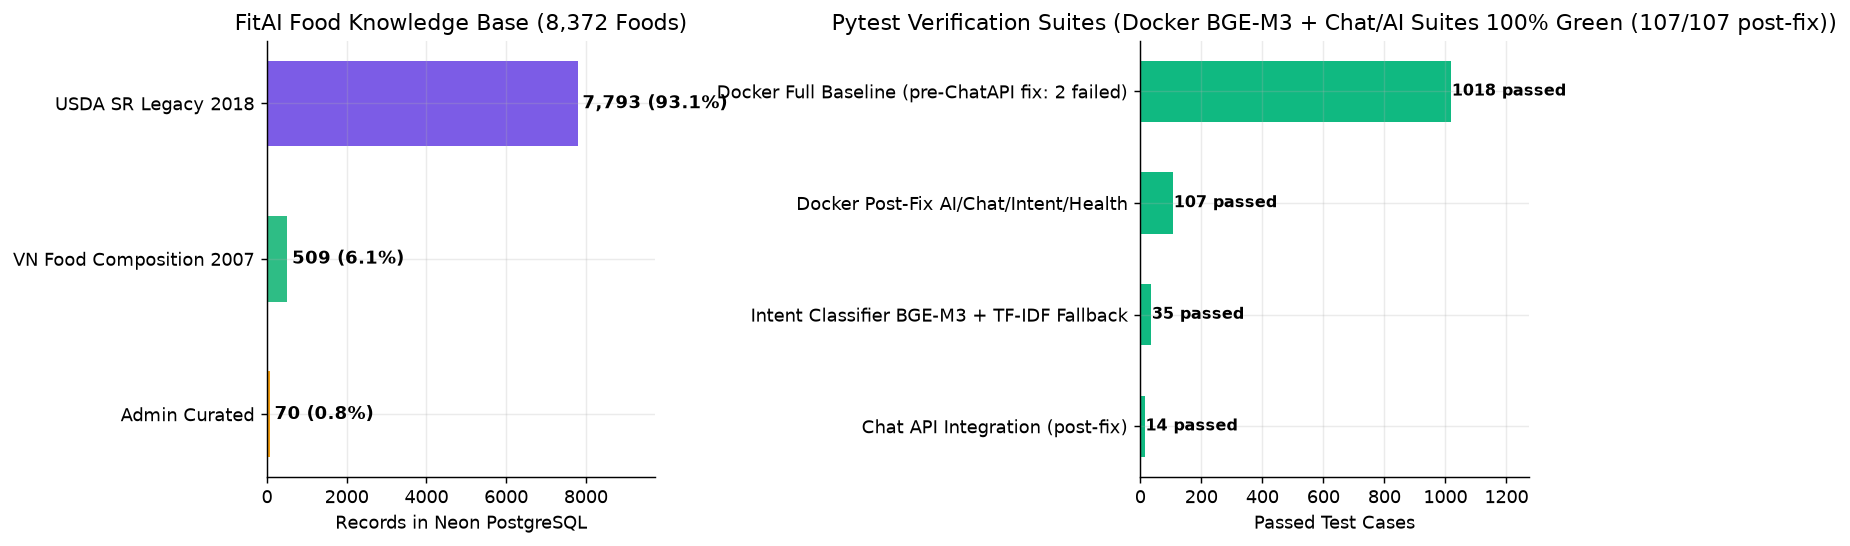

In [2]:
from core.database import AsyncSessionLocal
from models.food import Food
from models.food_source import FoodSource
from models.training_progress import WorkoutLog
from services.knowledge.vector_store import get_client, get_collection

async with AsyncSessionLocal() as db:
    food_rows = (
        await db.execute(
            select(FoodSource.code, func.count(Food.id))
            .join(Food, Food.source_id == FoodSource.id)
            .group_by(FoodSource.code)
        )
    ).all()
    workout_count = (await db.execute(select(func.count(WorkoutLog.id)))).scalar_one()

counts = dict(food_rows)
vn_count = counts.get("VN2007", 0)
admin_count = counts.get("ADMIN_MANUAL", 0)
usda_count = counts.get("USDA_SR_LEGACY_2018", 0)
total_foods = vn_count + admin_count + usda_count

try:
    chroma_count = get_collection(get_client()).count()
except Exception as exc:
    chroma_count = f"Unavailable ({type(exc).__name__})"

try:
    with urllib.request.urlopen("http://localhost:8000/health", timeout=3) as r:
        health_payload = json.loads(r.read().decode("utf-8"))
except Exception as exc:
    health_payload = {"error": str(exc)}

pytest_summary_path = RESULTS_DIR / "pytest_summary.json"
pytest_stats = json.loads(pytest_summary_path.read_text(encoding="utf-8")) if pytest_summary_path.exists() else {}

print(f"Backend /health : {health_payload}")
print(f"ChromaDB chunks : {chroma_count}")
print(f"Foods in Neon DB: VN2007={vn_count}, ADMIN_MANUAL={admin_count}, USDA={usda_count} -> TOTAL={total_foods}")
print(f"WorkoutLog rows : {workout_count}")
if pytest_stats:
    print("Pytest v3 audit :", pytest_stats)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3))

src_labels = ["USDA SR Legacy 2018", "VN Food Composition 2007", "Admin Curated"]
src_vals = [usda_count, vn_count, admin_count]
src_colors = ["#7c5ce6", "#2ebd85", "#f59e0b"]
bars = ax1.barh(src_labels[::-1], src_vals[::-1], color=src_colors[::-1], height=0.55)
for bar, val in zip(bars, src_vals[::-1]):
    pct = val / total_foods * 100 if total_foods else 0
    ax1.text(val + 120, bar.get_y() + bar.get_height() / 2, f"{val:,} ({pct:.1f}%)", va="center", fontweight="bold")
ax1.set_xlim(0, max(src_vals) * 1.25)
ax1.set_xlabel("Records in Neon PostgreSQL")
ax1.set_title(f"FitAI Food Knowledge Base ({total_foods:,} Foods)")

if pytest_stats.get("suites"):
    s_names = [s["name"] for s in pytest_stats["suites"]]
    s_passed = [s["passed"] for s in pytest_stats["suites"]]
    bars2 = ax2.barh(s_names[::-1], s_passed[::-1], color="#10b981", height=0.55)
    for bar, val in zip(bars2, s_passed[::-1]):
        ax2.text(val + 3, bar.get_y() + bar.get_height() / 2, f"{val} passed", va="center", fontweight="bold", fontsize=9)
    ax2.set_xlim(0, max(s_passed) * 1.25)
    ax2.set_xlabel("Passed Test Cases")
    ax2.set_title(f"Pytest Verification Suites ({pytest_stats.get('headline', '')})")
else:
    ax2.text(0.5, 0.5, f"ChromaDB RAG Chunks: {chroma_count}\nBackend: {health_payload.get('status', 'n/a')}", ha="center", va="center")
    ax2.set_axis_off()

plt.tight_layout()
plt.savefig(CHARTS_DIR / "01_system_data_and_tests_v3.png", bbox_inches="tight")
plt.show()

## 2. Intent Classifier v3 (`BAAI/bge-m3`) vs Baseline v2 (`TF-IDF`)
Đánh giá bộ phân loại nâng cấp **`BAAI/bge-m3` đóng băng + Softmax Logistic Regression** trên đúng **52 câu held-out** của `evaluation_v2`, so sánh trực tiếp Confusion Matrix, Macro-F1, Guardrail OOS Block Rate (TPR), In-Domain FPR và tốc độ suy luận CPU.

/Users/haidongnguyen/Google Drive Universal/fitai/backend/.venv/lib/python3.11/site-packages/google/api_core/_python_version_support.py:273: FutureWarning: You are using a Python version (3.11.17) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


/Users/haidongnguyen/Google Drive Universal/fitai/backend/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Active Intent Backend: bge-m3 (warmup=3344.7 ms)


Unseen Held-Out Accuracy (52 queries): 98.1% (51/52)
Macro-F1: 97.9% | Food Slot Extraction: 100.0% | Median CPU Latency: 40.0 ms
Guardrail OOS Block Rate (TPR): 100.0% | In-Domain False Block Rate (FPR): 0.0%

Remaining misclassified cases (v3):
  - 'chào fitai mình mới dùng app': gold=coaching_general -> pred=out_of_scope (0.343)


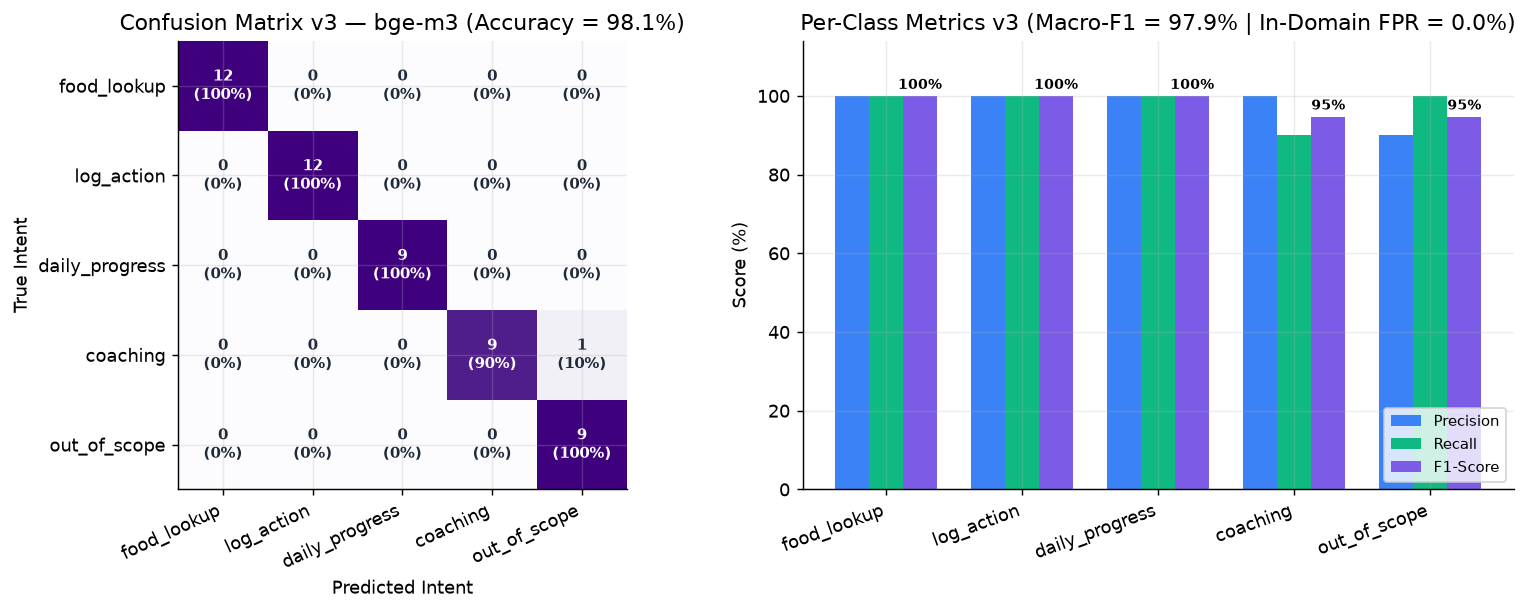


Fixed from v2 -> v3 (7 queries):
  + 'bữa giờ trong 7 ngày qua cân nặng tăng hay giảm': log_action -> daily_progress (0.364)
  + 'how much protein did i eat today': out_of_scope -> daily_progress (0.696)
  + 'what is my calorie average over the last 7 days': out_of_scope -> daily_progress (0.829)
  + 'so sánh thịt bò và ức gà món nào nhiều đạm hơn': food_lookup -> coaching_general (0.760)
  + 'cách tính TDEE cho người tập 4 buổi 1 tuần': log_action -> coaching_general (0.665)
  + 'hướng dẫn kỹ thuật deadlift đúng form': out_of_scope -> coaching_general (0.562)
  + 'who khuyến cáo người lớn nên tập mấy ngày một tuần': out_of_scope -> coaching_general (0.558)


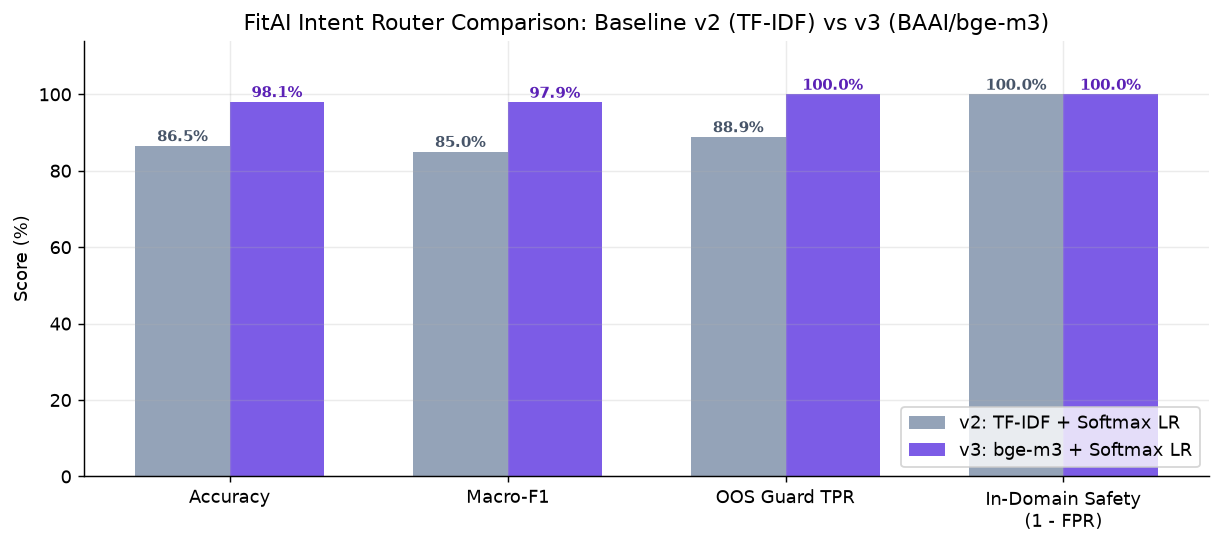

In [3]:
from services.intent_classifier import (
    INTENT_COACHING_GENERAL,
    INTENT_DAILY_PROGRESS,
    INTENT_FOOD_LOOKUP,
    INTENT_LOG_ACTION,
    INTENT_OUT_OF_SCOPE,
    classify_intent,
    extract_food_lookup_slot,
    get_intent_backend,
    is_out_of_scope,
    warmup_intent_classifier,
)

t_warm = time.perf_counter()
active_backend = warmup_intent_classifier()
warmup_ms = (time.perf_counter() - t_warm) * 1000.0
print(f"Active Intent Backend: {active_backend} (warmup={warmup_ms:.1f} ms)")

HELD_OUT_V3 = [
    # food_lookup (12)
    ("tôm hùm 300g bao nhiêu calo?", INTENT_FOOD_LOOKUP),
    ("100g hạt hướng dương bao nhiêu đạm?", INTENT_FOOD_LOOKUP),
    ("trứng vịt lộn 100g có bao nhiêu kcal", INTENT_FOOD_LOOKUP),
    ("thông tin dinh dưỡng cá thu 150g", INTENT_FOOD_LOOKUP),
    ("hạt chia 20g bao nhiêu chất xơ", INTENT_FOOD_LOOKUP),
    ("tra cứu sữa đậu nành", INTENT_FOOD_LOOKUP),
    ("giá trị dinh dưỡng của cua biển", INTENT_FOOD_LOOKUP),
    ("250g ức gà luộc bao nhiêu calo?", INTENT_FOOD_LOOKUP),
    ("nutrition facts for 150g salmon", INTENT_FOOD_LOOKUP),
    ("how many calories in 100g cheddar cheese", INTENT_FOOD_LOOKUP),
    ("macros for 200g broccoli", INTENT_FOOD_LOOKUP),
    ("protein in 180g beef steak", INTENT_FOOD_LOOKUP),
    # log_action: meal + body metric + workout (12)
    ("ghi 200g cá hồi bữa tối", INTENT_LOG_ACTION),
    ("lưu 120g ức gà vào nhật ký", INTENT_LOG_ACTION),
    ("mới ăn 150g bún bò", INTENT_LOG_ACTION),
    ("thêm 50g yến mạch bữa sáng", INTENT_LOG_ACTION),
    ("hôm nay cân nặng 71.2kg", INTENT_LOG_ACTION),
    ("cập nhật cân nặng 64kg vòng eo 75cm", INTENT_LOG_ACTION),
    ("chạy bộ 30 phút mức vừa", INTENT_LOG_ACTION),
    ("mới tập gym 45 phút", INTENT_LOG_ACTION),
    ("vừa đạp xe 40 phút xong", INTENT_LOG_ACTION),
    ("ghi 50 phút bơi lội hôm nay", INTENT_LOG_ACTION),
    ("log 100g oatmeal for breakfast", INTENT_LOG_ACTION),
    ("log 45 min strength workout", INTENT_LOG_ACTION),
    # daily_progress (9)
    ("hôm nay tôi nạp được bao nhiêu calo rồi", INTENT_DAILY_PROGRESS),
    ("xem lượng protein đã ăn hôm nay", INTENT_DAILY_PROGRESS),
    ("bữa giờ trong 7 ngày qua cân nặng tăng hay giảm", INTENT_DAILY_PROGRESS),
    ("trung bình 30 ngày gần nhất ăn bao nhiêu kcal", INTENT_DAILY_PROGRESS),
    ("hôm nay còn được ăn thêm bao nhiêu calo nữa", INTENT_DAILY_PROGRESS),
    ("tuần này mình tập luyện được bao nhiêu phút rồi", INTENT_DAILY_PROGRESS),
    ("kiểm tra tổng kết bữa ăn hôm nay", INTENT_DAILY_PROGRESS),
    ("how much protein did i eat today", INTENT_DAILY_PROGRESS),
    ("what is my calorie average over the last 7 days", INTENT_DAILY_PROGRESS),
    # coaching_general (10)
    ("200g cơm trắng ăn buổi tối có sợ mập không", INTENT_COACHING_GENERAL),
    ("so sánh thịt bò và ức gà món nào nhiều đạm hơn", INTENT_COACHING_GENERAL),
    ("cách tính TDEE cho người tập 4 buổi 1 tuần", INTENT_COACHING_GENERAL),
    ("tư vấn lịch tập cho người mới bắt đầu giảm mỡ", INTENT_COACHING_GENERAL),
    ("hướng dẫn kỹ thuật deadlift đúng form", INTENT_COACHING_GENERAL),
    ("who khuyến cáo người lớn nên tập mấy ngày một tuần", INTENT_COACHING_GENERAL),
    ("tôi muốn tăng cơ nạc thì nên ăn dư bao nhiêu calo", INTENT_COACHING_GENERAL),
    ("chào fitai mình mới dùng app", INTENT_COACHING_GENERAL),
    ("should i eat banana before cardio", INTENT_COACHING_GENERAL),
    ("compare whey protein vs chicken breast", INTENT_COACHING_GENERAL),
    # out_of_scope (9)
    ("dự báo thời tiết hà nội cuối tuần này", INTENT_OUT_OF_SCOPE),
    ("giá vàng sjc hôm nay tăng hay giảm", INTENT_OUT_OF_SCOPE),
    ("viết đoạn code javascript gọi api fetch", INTENT_OUT_OF_SCOPE),
    ("chỉ mình cách nấu món thịt kho tàu ngon", INTENT_OUT_OF_SCOPE),
    ("làm một bài thơ lục bát về biển", INTENT_OUT_OF_SCOPE),
    ("tối nay đội tuyển việt nam đá lúc mấy giờ", INTENT_OUT_OF_SCOPE),
    ("how to install docker on ubuntu", INTENT_OUT_OF_SCOPE),
    ("tell me a funny programming joke", INTENT_OUT_OF_SCOPE),
    ("what is the stock price of apple today", INTENT_OUT_OF_SCOPE),
]

LABELS = [INTENT_FOOD_LOOKUP, INTENT_LOG_ACTION, INTENT_DAILY_PROGRESS, INTENT_COACHING_GENERAL, INTENT_OUT_OF_SCOPE]
SHORT = ["food_lookup", "log_action", "daily_progress", "coaching", "out_of_scope"]
idx_map = {lbl: i for i, lbl in enumerate(LABELS)}
cm = np.zeros((len(LABELS), len(LABELS)), dtype=int)

intent_rows = []
latencies_ms = []
for text, gold in HELD_OUT_V3:
    t0 = time.perf_counter()
    pred = classify_intent(text)
    lat_ms = (time.perf_counter() - t0) * 1000.0
    latencies_ms.append(lat_ms)
    cm[idx_map[gold], idx_map[pred.intent]] += 1
    slot = extract_food_lookup_slot(text)
    intent_rows.append({
        "query": text,
        "gold_intent": gold,
        "pred_intent": pred.intent,
        "confidence": round(pred.confidence, 4),
        "correct": pred.intent == gold,
        "latency_ms": round(lat_ms, 2),
        "slot_query": slot.query if slot else None,
        "slot_grams": slot.grams if slot else None,
        "oos_blocked": is_out_of_scope(text),
    })

df_intent = pd.DataFrame(intent_rows)
df_intent.to_csv(RESULTS_DIR / "eval_v3_intent_results.csv", index=False, encoding="utf-8-sig")

acc = float(df_intent["correct"].mean())
precisions, recalls, f1s = [], [], []
for i in range(len(LABELS)):
    tp = cm[i, i]
    fp = cm[:, i].sum() - tp
    fn = cm[i, :].sum() - tp
    p = tp / (tp + fp) if (tp + fp) else 0.0
    r = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = (2 * p * r / (p + r)) if (p + r) else 0.0
    precisions.append(p); recalls.append(r); f1s.append(f1)

macro_f1 = float(np.mean(f1s))
oos_df = df_intent[df_intent["gold_intent"] == INTENT_OUT_OF_SCOPE]
in_df = df_intent[df_intent["gold_intent"] != INTENT_OUT_OF_SCOPE]
oos_tpr = float(oos_df["oos_blocked"].mean())
in_fpr = float(in_df["oos_blocked"].mean())
slot_ok = float(df_intent[df_intent["gold_intent"] == INTENT_FOOD_LOOKUP]["slot_query"].notna().mean())
p50_intent_ms = float(np.median(latencies_ms))

print(f"Unseen Held-Out Accuracy ({len(HELD_OUT_V3)} queries): {acc*100:.1f}% ({df_intent['correct'].sum()}/{len(HELD_OUT_V3)})")
print(f"Macro-F1: {macro_f1*100:.1f}% | Food Slot Extraction: {slot_ok*100:.1f}% | Median CPU Latency: {p50_intent_ms:.1f} ms")
print(f"Guardrail OOS Block Rate (TPR): {oos_tpr*100:.1f}% | In-Domain False Block Rate (FPR): {in_fpr*100:.1f}%")

misses = df_intent[~df_intent["correct"]]
if not misses.empty:
    print("\nRemaining misclassified cases (v3):")
    for _, row in misses.iterrows():
        print(f"  - {row['query']!r}: gold={row['gold_intent']} -> pred={row['pred_intent']} ({row['confidence']:.3f})")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.8))
cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
ax1.imshow(cm_norm, cmap="Purples", vmin=0, vmax=1)
ax1.set_xticks(range(len(SHORT)), SHORT, rotation=25, ha="right")
ax1.set_yticks(range(len(SHORT)), SHORT)
ax1.set_xlabel("Predicted Intent")
ax1.set_ylabel("True Intent")
ax1.set_title(f"Confusion Matrix v3 — {active_backend} (Accuracy = {acc*100:.1f}%)")
for r in range(len(LABELS)):
    for c in range(len(LABELS)):
        cnt = cm[r, c]
        txt_color = "white" if cm_norm[r, c] > 0.55 else "#1f2937"
        ax1.text(c, r, f"{cnt}\n({cm_norm[r, c]*100:.0f}%)", ha="center", va="center", color=txt_color, fontsize=8.5, fontweight="bold")

x = np.arange(len(SHORT))
w = 0.25
ax2.bar(x - w, [v * 100 for v in precisions], w, label="Precision", color="#3b82f6")
ax2.bar(x, [v * 100 for v in recalls], w, label="Recall", color="#10b981")
ax2.bar(x + w, [v * 100 for v in f1s], w, label="F1-Score", color="#7c5ce6")
ax2.set_xticks(x, SHORT, rotation=20, ha="right")
ax2.set_ylim(0, 114)
ax2.set_ylabel("Score (%)")
ax2.set_title(f"Per-Class Metrics v3 (Macro-F1 = {macro_f1*100:.1f}% | In-Domain FPR = {in_fpr*100:.1f}%)")
ax2.legend(loc="lower right", frameon=True, fontsize=8.5)
for xi, f1_v in zip(x, f1s):
    ax2.text(xi + w, f1_v * 100 + 1.8, f"{f1_v*100:.0f}%", ha="center", fontsize=8, fontweight="bold")

plt.tight_layout()
plt.savefig(CHARTS_DIR / "02_intent_confusion_and_f1_v3.png", bbox_inches="tight")
plt.show()

# Đối chiếu trực tiếp với Baseline v2 (TF-IDF) nếu có kết quả v2
v2_summary_path = EVAL_V2_DIR / "results" / "eval_v2_summary.json"
v2_csv_path = EVAL_V2_DIR / "results" / "eval_v2_intent_results.csv"
if v2_summary_path.exists() and v2_csv_path.exists():
    v2_sum = json.loads(v2_summary_path.read_text(encoding="utf-8"))
    df_v2 = pd.read_csv(v2_csv_path)
    merged = df_v2[["query", "gold_intent", "pred_intent", "correct", "oos_blocked"]].merge(
        df_intent[["query", "pred_intent", "confidence", "correct", "oos_blocked"]],
        on="query",
        suffixes=("_v2", "_v3"),
    )
    fixed = merged[(~merged["correct_v2"]) & (merged["correct_v3"])]
    print(f"\nFixed from v2 -> v3 ({len(fixed)} queries):")
    for _, row in fixed.iterrows():
        print(f"  + {row['query']!r}: {row['pred_intent_v2']} -> {row['pred_intent_v3']} ({row['confidence']:.3f})")

    comp_metrics = ["Accuracy", "Macro-F1", "OOS Guard TPR", "In-Domain Safety\n(1 - FPR)"]
    v2_vals = [
        v2_sum["intent_v2_accuracy"] * 100,
        v2_sum["intent_v2_macro_f1"] * 100,
        v2_sum["intent_v2_oos_tpr"] * 100,
        (1.0 - v2_sum["intent_v2_in_domain_fpr"]) * 100,
    ]
    v3_vals = [acc * 100, macro_f1 * 100, oos_tpr * 100, (1.0 - in_fpr) * 100]

    fig_cmp, ax_c = plt.subplots(figsize=(9.5, 4.3))
    xc = np.arange(len(comp_metrics))
    wc = 0.34
    b1 = ax_c.bar(xc - wc/2, v2_vals, wc, label="v2: TF-IDF + Softmax LR", color="#94a3b8")
    b2 = ax_c.bar(xc + wc/2, v3_vals, wc, label=f"v3: {active_backend} + Softmax LR", color="#7c5ce6")
    for b in b1:
        ax_c.text(b.get_x() + b.get_width()/2, b.get_height() + 1.2, f"{b.get_height():.1f}%", ha="center", fontsize=8.5, color="#475569", fontweight="bold")
    for b in b2:
        ax_c.text(b.get_x() + b.get_width()/2, b.get_height() + 1.2, f"{b.get_height():.1f}%", ha="center", fontsize=8.5, color="#5b21b6", fontweight="bold")
    ax_c.set_xticks(xc, comp_metrics)
    ax_c.set_ylim(0, 114)
    ax_c.set_ylabel("Score (%)")
    ax_c.set_title("FitAI Intent Router Comparison: Baseline v2 (TF-IDF) vs v3 (BAAI/bge-m3)")
    ax_c.legend(loc="lower right", frameon=True)
    plt.tight_layout()
    plt.savefig(CHARTS_DIR / "02b_v2_vs_v3_comparison.png", bbox_inches="tight")
    plt.show()

## 3. Data & Numerical Plausibility Audit (`Kiểm tra số liệu trả về`)
Xác minh 14 món Việt–Anh trọng điểm (bao gồm hồi quy `300g tôm hùm`, Atwater, chặn đồ khô ngoài ý muốn), ngưỡng tự tin OPUS-MT (`0.55`), `BMI/BMR/TDEE` và tổng hợp tuần `WorkoutLog`.

          query  grams                                        picked_food    prep  kcal  protein_g  fat_g  carb_g  plausible
        tôm hùm  300.0 Crustaceans, lobster, northern, cooked, moist heat  cooked 267.0       57.0    2.6     0.0       True
    tôm hùm hấp  300.0 Crustaceans, lobster, northern, cooked, moist heat  cooked 267.0       57.0    2.6     0.0       True
        tôm khô  100.0                                            Tôm khô   dried 347.0       75.6    3.8     2.5       True
          ức gà  150.0                     Ức gà nướng chín (thịt, bỏ da)  cooked 247.5       46.5    5.4     0.0       True
      cơm trắng  200.0               Gạo trắng nấu chín (cơm, không muối)  cooked 260.0        5.4    0.6    55.5       True
         phở bò  500.0                              Phở bò (1 tô ≈ 500 g)  cooked 379.5       24.5    9.7    47.0       True
hạt hướng dương  100.0            Oil, sunflower, linoleic, (approx. 65%) unknown 884.0        0.0  100.0     0.0       True



OPUS-MT Confidence Gate Audit (threshold = 0.55):
          query direction        raw_nmt  confidence  passed_gate
hạt hướng dương     vi-en      sunflower    0.621938         True
       trà xanh     vi-en     Green tea.    0.599661         True
       cải xoăn     vi-en           kale    0.570535         True
      dầu ô liu     vi-en      olive oil    0.897187         True
        nấm rơm     vi-en         straw.    0.336907        False
         bơ quả     vi-en  Apple butter.    0.083543        False
         cà rốt     vi-en It's a carrot.    0.001740        False
 grilled salmon     en-vi   Cá hồi nướng    0.927036         True
     white rice     en-vi      gạo trắng    0.688021         True
   dragon fruit     en-vi   Hoa quả rồng    0.003085        False

Body Metrics Audit -> BMI=23.5, BMR=1688.75, TDEE=2617.56, Target=2225 kcal (Macro sum=2226 kcal)
WorkoutLog Weekly Audit -> active_dates=2, completed_days=1, workout_sessions=2, total_minutes=95


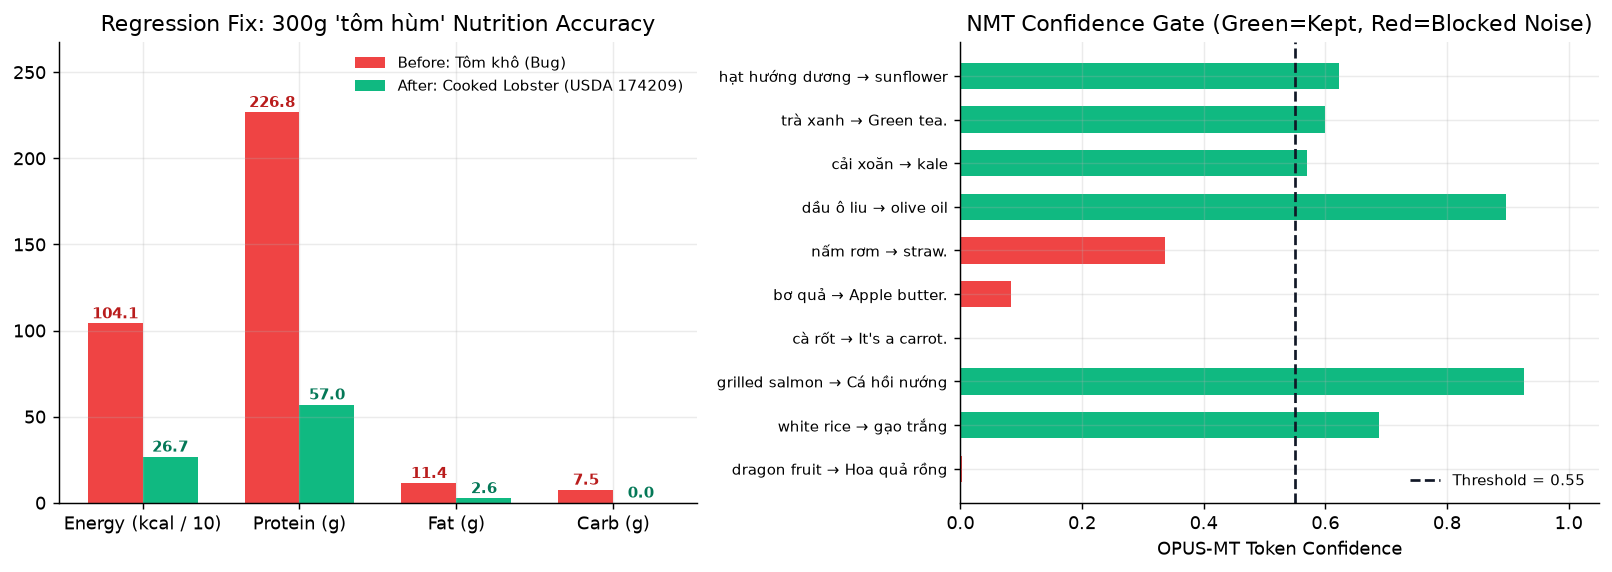

In [4]:
from types import SimpleNamespace
from models.profile import ActivityLevel, FitnessGoal
from services.foods.lookup import resolve_best_food, scale
from services.foods.preparation import FoodPreparation
from services.foods.translator import _cached_translate, translate_food_query
from services.metrics_service import profile_metrics_summary
from services.training.progress import build_week_summary

FOOD_AUDIT_CASES = [
    ("tôm hùm", 300.0, False, "Cooked lobster (~267 kcal, 57g P), NOT Tôm khô"),
    ("tôm hùm hấp", 300.0, False, "Cooked lobster"),
    ("tôm khô", 100.0, True, "Explicit dried request"),
    ("ức gà", 150.0, False, "Grilled/cooked chicken breast"),
    ("cơm trắng", 200.0, False, "USDA cooked white rice"),
    ("phở bò", 500.0, False, "VN dish / Admin bowl"),
    ("hạt hướng dương", 100.0, False, "Translated via OPUS-MT vi-en"),
    ("việt quất", 150.0, False, "Blueberries, raw"),
    ("cải xoăn", 100.0, False, "Kale cooked/raw"),
    ("sò điệp", 150.0, False, "Cooked scallop via VI_EN_PHRASES"),
    ("bạch tuộc", 150.0, False, "Cooked octopus"),
    ("water spinach", 200.0, False, "EN->VI Rau muống"),
    ("sweet potato", 200.0, False, "EN->VI Khoai lang"),
    ("cá hồi", 150.0, False, "Cooked Atlantic salmon"),
]

food_audit_rows = []
async with AsyncSessionLocal() as db:
    dried_shrimp = (await db.execute(select(Food).where(Food.code == 8053))).scalar_one()
    for q, grams, allow_dried, note in FOOD_AUDIT_CASES:
        food, resolve_note = await resolve_best_food(db, q)
        if food is None:
            food_audit_rows.append({"query": q, "grams": grams, "matched": False, "plausible": False, "issue": "No match"})
            continue
        kcal = scale(food.energy_kcal, grams)
        p = scale(food.protein_g, grams)
        f = scale(food.fat_g, grams)
        c = scale(food.carb_g, grams)
        prep = food.preparation.value if hasattr(food.preparation, "value") else str(food.preparation)
        atwater = None if None in (p, f, c) else round(4.0 * p + 9.0 * f + 4.0 * c, 1)
        atwater_diff = None if (atwater is None or kcal is None) else round(abs(kcal - atwater), 1)
        macro_sum_ok = True if None in (p, f, c) else ((p + f + c) <= grams + 1.0)
        dried_ok = True if allow_dried else (prep != FoodPreparation.DRIED.value)
        kcal_ok = (kcal is None) or (0 <= kcal <= grams * 9.2)
        plausible = macro_sum_ok and dried_ok and kcal_ok and (atwater_diff is None or atwater_diff <= max(25.0, kcal * 0.25))
        food_audit_rows.append({
            "query": q,
            "grams": grams,
            "picked_food": food.name_vi,
            "prep": prep,
            "kcal": kcal,
            "protein_g": p,
            "fat_g": f,
            "carb_g": c,
            "atwater_kcal": atwater,
            "atwater_diff": atwater_diff,
            "dried_ok": dried_ok,
            "macro_sum_ok": macro_sum_ok,
            "plausible": plausible,
        })

df_food = pd.DataFrame(food_audit_rows)
df_food.to_csv(RESULTS_DIR / "eval_v3_food_checks.csv", index=False, encoding="utf-8-sig")
print(df_food[["query", "grams", "picked_food", "prep", "kcal", "protein_g", "fat_g", "carb_g", "plausible"]].to_string(index=False))
print(f"\nFood Numerical Plausibility Pass Rate: {df_food['plausible'].sum()}/{len(df_food)} ({df_food['plausible'].mean()*100:.1f}%)")

NMT_AUDIT = [
    ("vi-en", "hạt hướng dương"), ("vi-en", "trà xanh"), ("vi-en", "cải xoăn"),
    ("vi-en", "dầu ô liu"), ("vi-en", "nấm rơm"), ("vi-en", "bơ quả"), ("vi-en", "cà rốt"),
    ("en-vi", "grilled salmon"), ("en-vi", "white rice"), ("en-vi", "dragon fruit"),
]
nmt_rows = []
for direction, q in NMT_AUDIT:
    raw_txt, conf = _cached_translate(direction, f"{direction}:{q}", q)
    kept = bool(await translate_food_query(q))
    nmt_rows.append({"query": q, "direction": direction, "raw_nmt": raw_txt, "confidence": conf, "passed_gate": kept})
df_nmt = pd.DataFrame(nmt_rows)
print("\nOPUS-MT Confidence Gate Audit (threshold = 0.55):")
print(df_nmt.to_string(index=False))

sample_profile = SimpleNamespace(
    age=26, gender="male", height_cm=175.0, weight_kg=72.0,
    activity_level=ActivityLevel.MODERATE.value, fitness_goal=FitnessGoal.WEIGHT_LOSS.value,
)
bm = profile_metrics_summary(sample_profile)
macro_kcal = 4 * bm["protein_g"] + 9 * bm["fat_g"] + 4 * bm["carb_g"]
wk = build_week_summary(date(2026, 11, 16), [(date(2026, 11, 16), 20)], [(date(2026, 11, 16), 30), (date(2026, 11, 18), 45)])
print(f"\nBody Metrics Audit -> BMI={bm['bmi']}, BMR={bm['bmr']}, TDEE={bm['tdee']}, Target={bm['target_calories']} kcal (Macro sum={macro_kcal:.0f} kcal)")
print(f"WorkoutLog Weekly Audit -> active_dates={wk['active_dates']}, completed_days={wk['completed_days']}, workout_sessions={wk['workout_sessions']}, total_minutes={wk['total_minutes']}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.5))
old_kcal, old_p = scale(dried_shrimp.energy_kcal, 300), scale(dried_shrimp.protein_g, 300)
new_row = df_food[df_food["query"] == "tôm hùm"].iloc[0]
metrics_lbl = ["Energy (kcal / 10)", "Protein (g)", "Fat (g)", "Carb (g)"]
old_vals = [old_kcal / 10.0, old_p, scale(dried_shrimp.fat_g, 300), scale(dried_shrimp.carb_g, 300)]
new_vals = [new_row["kcal"] / 10.0, new_row["protein_g"], new_row["fat_g"], new_row["carb_g"]]
x = np.arange(len(metrics_lbl))
w = 0.35
ax1.bar(x - w/2, old_vals, w, label="Before: Tôm khô (Bug)", color="#ef4444")
ax1.bar(x + w/2, new_vals, w, label="After: Cooked Lobster (USDA 174209)", color="#10b981")
for xi, ov, nv in zip(x, old_vals, new_vals):
    ax1.text(xi - w/2, ov + 3, f"{ov:.1f}", ha="center", fontsize=8.5, color="#b91c1c", fontweight="bold")
    ax1.text(xi + w/2, nv + 3, f"{nv:.1f}", ha="center", fontsize=8.5, color="#047857", fontweight="bold")
ax1.set_xticks(x, metrics_lbl)
ax1.set_ylim(0, max(old_vals) * 1.18)
ax1.set_title("Regression Fix: 300g 'tôm hùm' Nutrition Accuracy")
ax1.legend(frameon=False, fontsize=8.5)

colors_nmt = ["#10b981" if ok else "#ef4444" for ok in df_nmt["passed_gate"]]
y_pos = np.arange(len(df_nmt))
ax2.barh(y_pos, df_nmt["confidence"], color=colors_nmt, height=0.6)
ax2.axvline(settings.FOOD_NMT_MIN_CONFIDENCE, color="#111827", linestyle="--", linewidth=1.5, label=f"Threshold = {settings.FOOD_NMT_MIN_CONFIDENCE}")
ax2.set_yticks(y_pos, [f"{r['query']} → {r['raw_nmt'][:16]}" for _, r in df_nmt.iterrows()], fontsize=8.5)
ax2.invert_yaxis()
ax2.set_xlim(0, 1.05)
ax2.set_xlabel("OPUS-MT Token Confidence")
ax2.set_title("NMT Confidence Gate (Green=Kept, Red=Blocked Noise)")
ax2.legend(loc="lower right", frameon=False, fontsize=8.5)

plt.tight_layout()
plt.savefig(CHARTS_DIR / "03_nutrition_accuracy_and_nmt_v3.png", bbox_inches="tight")
plt.show()

## 4. End-to-End Chatbot Response & Grounding Evaluation (`test respond`)
Chạy kiểm thử phản hồi thực tế qua cả **Fast-Path (`try_fast_route` dùng `BAAI/bge-m3`)** lẫn **Full Live Gemini 2.5 Flash Agent (`InProcessChat` trên FastAPI + Neon DB + ChromaDB RAG)**.

Key 'title' is not supported in schema, ignoring


Key 'title' is not supported in schema, ignoring


Key 'title' is not supported in schema, ignoring


Key 'title' is not supported in schema, ignoring


Key 'title' is not supported in schema, ignoring


Key 'title' is not supported in schema, ignoring


... (24 outputs left out)

/Users/haidongnguyen/Google Drive Universal/fitai/backend/.venv/lib/python3.11/site-packages/langchain_google_genai/chat_models.py:381: UserWarning: Convert_system_message_to_human will be deprecated!
  warnings.warn("Convert_system_message_to_human will be deprecated!")


Retrying langchain_google_genai.chat_models._achat_with_retry.<locals>._achat_with_retry in 2.0 seconds as it raised ResourceExhausted: 429 You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://aistudio.google.com/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. 
* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-2.5-flash, description: Generate content requests per day limit exceeded on Free Tier. See https://aistudio.google.com/docs/rate-limits.
Please retry in 12h28m30.238898614s. [links {
  description: "Learn more about Gemini API quotas"
  url: "https://aistudio.google.com/docs/rate-limits"
}
, violations {
  description: "Generate content requests per day limit exceeded on Free Tier. See https://aistudio.google.com/docs/rate-limits."
  quota_metric: "generativelanguage.googleapis.com/generate_con

FitnessAdvisorAgent error: ResourceExhausted


   id                 group       mode  latency_ms                                         tools  sources_count passed                                     notes
 FP01          Fast-Path DB fast_route      4096.4                    (fast-path/bge-m3 / 0 LLM)              2   True                                        OK
 FP02          Fast-Path DB fast_route       523.9                    (fast-path/bge-m3 / 0 LLM)              4   True                                        OK
 FP03          Fast-Path DB fast_route       697.2                    (fast-path/bge-m3 / 0 LLM)              4   True                                        OK
 FP04      Ambiguity Safety fast_route       522.0                    (fast-path/bge-m3 / 0 LLM)              0   True                                        OK
 FP05       Raw-Only Safety fast_route       593.4                    (fast-path/bge-m3 / 0 LLM)              0   True                                        OK
OOS01    Out-of-Scope Guard fast_r

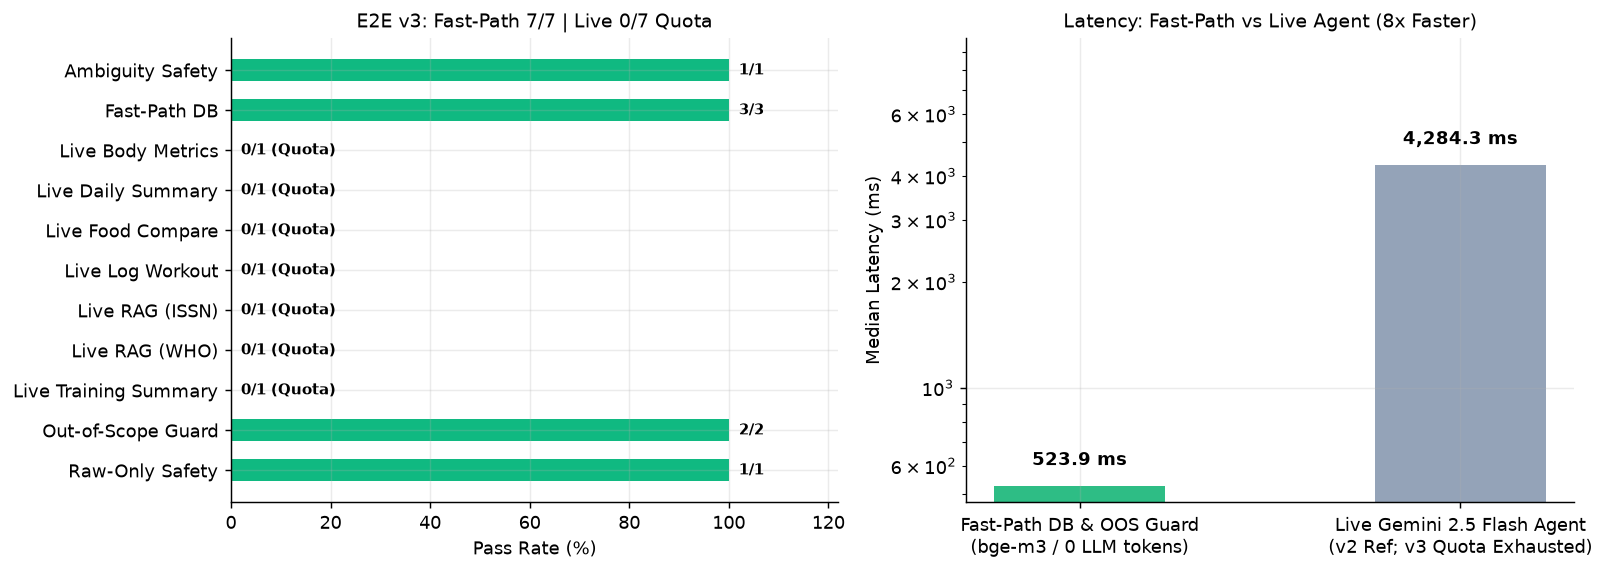

In [5]:
from evaluation.accounts import ensure_accounts
from evaluation.checks import METRIC_TOLERANCE, contains_value
from evaluation.inprocess import InProcessChat, app_client, instrument_agent
from evaluation.questions import ACCOUNT_SAMPLE, Question
from services.intent_classifier import try_fast_route

E2E_CASES = [
    ("FP01", "Fast-Path DB", "fast_route", ACCOUNT_SAMPLE, "150g ức gà bao nhiêu calo?", {"expect_sub": "150 g", "expect_num": 180.0}),
    ("FP02", "Fast-Path DB", "fast_route", ACCOUNT_SAMPLE, "tôm hùm 300g bao nhiêu calo?", {"expect_sub": "lobster", "expect_num": 267.0}),
    ("FP03", "Fast-Path DB", "fast_route", ACCOUNT_SAMPLE, "hạt hướng dương 100g bao nhiêu calo?", {"expect_sub": "sunflower", "expect_num": 584.0}),
    ("FP04", "Ambiguity Safety", "fast_route", ACCOUNT_SAMPLE, "100g bơ bao nhiêu calo?", {"expect_sub": "nhiều loại"}),
    ("FP05", "Raw-Only Safety", "fast_route", ACCOUNT_SAMPLE, "150g xôi bao nhiêu calo?", {"expect_sub": "SỐNG"}),
    ("OOS01", "Out-of-Scope Guard", "fast_route", ACCOUNT_SAMPLE, "Giá vé World Cup bao nhiêu?", {"expect_sub": "ngoài phạm vi"}),
    ("OOS02", "Out-of-Scope Guard", "fast_route", ACCOUNT_SAMPLE, "tối nay đội tuyển việt nam đá lúc mấy giờ", {"expect_sub": "ngoài phạm vi"}),
    ("RAG01", "Live RAG (WHO)", "live_agent", ACCOUNT_SAMPLE, "Một tuần người lớn nên vận động bao nhiêu phút?", {"req_tool": "search_knowledge", "expect_num": 150.0, "req_source": True}),
    ("RAG02", "Live RAG (ISSN)", "live_agent", ACCOUNT_SAMPLE, "Ăn kiêng keto có đốt mỡ nhanh hơn low-fat khi cùng calo và protein không?", {"req_tool": "search_knowledge", "req_source": True}),
    ("BM01", "Live Body Metrics", "live_agent", ACCOUNT_SAMPLE, "Tính chỉ số BMI, BMR và TDEE của tôi giúp nhé", {"req_tool": "calc_body_metrics", "check_bm": True}),
    ("DM01", "Live Daily Summary", "live_agent", ACCOUNT_SAMPLE, "Hôm nay tôi đã ăn tổng cộng bao nhiêu calo rồi?", {"req_tool": "get_daily_summary", "check_summary": True}),
    ("FD01", "Live Food Compare", "live_agent", ACCOUNT_SAMPLE, "So sánh lượng đạm giữa 150g ức gà và 150g cá hồi", {"req_tool": "lookup_food", "req_source": True}),
    ("WL01", "Live Log Workout", "live_agent", ACCOUNT_SAMPLE, "Hôm nay tôi vừa chạy bộ 30 phút mức vừa, ghi vào nhật ký giúp tôi", {"req_tool": "log_workout", "expect_num": 30.0}),
    ("DP01", "Live Training Summary", "live_agent", ACCOUNT_SAMPLE, "Tuần này tôi đã tập luyện được bao nhiêu phút rồi?", {"req_tool": "get_training_summary", "expect_num": 30.0}),
]

e2e_rows = []
live_quota_exhausted = False
async with app_client() as client:
    accounts = await ensure_accounts(client)
    h_full = accounts.headers(ACCOUNT_SAMPLE)
    ref_metrics = (await client.get("/api/v1/profile/metrics", headers=h_full)).json()
    ref_summary = (await client.get("/api/v1/meals/summary", headers=h_full)).json()
    chat_fn = InProcessChat(client, accounts)

    with instrument_agent():
        first_live = True
        for cid, grp, mode, acct, prompt, cfg in E2E_CASES:
            if mode == "fast_route":
                t0 = time.perf_counter()
                async with AsyncSessionLocal() as db:
                    fast_res = await try_fast_route(db, prompt)
                elapsed_ms = (time.perf_counter() - t0) * 1000.0
                reply = fast_res[0] if fast_res else ""
                sources = fast_res[1] if fast_res else []
                tools_called = []
                http_status = 200 if fast_res is not None else 500
                outcome_err = ""
            else:
                if live_quota_exhausted:
                    e2e_rows.append({
                        "id": cid,
                        "group": grp,
                        "mode": mode,
                        "http_status": 429,
                        "latency_ms": np.nan,
                        "tools": "(skipped — Gemini Free Tier 20 RPD exhausted)",
                        "sources_count": 0,
                        "passed": None,
                        "notes": "SKIPPED_QUOTA",
                        "reply_preview": "",
                    })
                    continue
                if not first_live:
                    await asyncio.sleep(28.0)
                first_live = False
                q_obj = Question(id=cid, nhom=grp, cau_hoi=prompt, chuan_bi="")
                t0 = time.perf_counter()
                outcome = await chat_fn(q_obj)
                elapsed_ms = (time.perf_counter() - t0) * 1000.0
                outcome_err = outcome.error_type or ""
                if outcome.http_status in (429, 503) and outcome_err == "ResourceExhausted":
                    live_quota_exhausted = True
                    e2e_rows.append({
                        "id": cid,
                        "group": grp,
                        "mode": mode,
                        "http_status": outcome.http_status,
                        "latency_ms": round(elapsed_ms, 1),
                        "tools": "(quota exhausted — 20 RPD Free Tier)",
                        "sources_count": 0,
                        "passed": None,
                        "notes": "SKIPPED_QUOTA (ResourceExhausted 429/503)",
                        "reply_preview": "",
                    })
                    continue
                reply = outcome.reply
                sources = outcome.sources
                tools_called = [c["name"] for c in outcome.calls]
                http_status = outcome.http_status

            passed = (http_status == 200 and bool(reply.strip()))
            notes = []
            if cfg.get("expect_sub") and cfg["expect_sub"].lower() not in reply.lower():
                passed = False
                notes.append(f"missing '{cfg['expect_sub']}'")
            if cfg.get("expect_num") is not None and not contains_value(reply, cfg["expect_num"], tol=1.0):
                passed = False
                notes.append(f"missing num {cfg['expect_num']}")
            if cfg.get("req_tool") and cfg["req_tool"] not in tools_called:
                passed = False
                notes.append(f"missing tool {cfg['req_tool']} (got {tools_called})")
            if cfg.get("req_source") and not sources:
                passed = False
                notes.append("missing sources")
            if cfg.get("check_bm"):
                bmi_ok = contains_value(reply, ref_metrics["bmi"], tol=METRIC_TOLERANCE)
                tdee_ok = contains_value(reply, ref_metrics["tdee"], tol=METRIC_TOLERANCE)
                if not (bmi_ok and tdee_ok):
                    passed = False
                    notes.append(f"metrics mismatch (expected BMI={ref_metrics['bmi']}, TDEE={ref_metrics['tdee']})")
            if cfg.get("check_summary"):
                eaten_kcal = (ref_summary.get("eaten") or {}).get("energy_kcal")
                if eaten_kcal is not None and not contains_value(reply, eaten_kcal, tol=1.0):
                    passed = False
                    notes.append(f"daily kcal mismatch (expected {eaten_kcal})")

            e2e_rows.append({
                "id": cid,
                "group": grp,
                "mode": mode,
                "http_status": http_status,
                "latency_ms": round(elapsed_ms, 1),
                "tools": ", ".join(tools_called) if tools_called else f"(fast-path/{active_backend} / 0 LLM)",
                "sources_count": len(sources),
                "passed": passed,
                "notes": "; ".join(notes) if notes else "OK",
                "reply_preview": reply.replace("\n", " ")[:160],
            })

df_e2e = pd.DataFrame(e2e_rows)
df_e2e.to_csv(RESULTS_DIR / "eval_v3_responses.csv", index=False, encoding="utf-8-sig")

df_fast = df_e2e[df_e2e["mode"] == "fast_route"]
df_live = df_e2e[df_e2e["mode"] == "live_agent"]
df_live_ran = df_live[df_live["passed"].notna()]
fast_pass_cnt = int(df_fast["passed"].sum())
live_pass_cnt = int(df_live_ran["passed"].sum()) if not df_live_ran.empty else 0
fast_p50_ms = round(float(df_fast["latency_ms"].median()), 1)
live_p50_ms = round(float(df_live_ran["latency_ms"].median()), 1) if not df_live_ran.empty else None

summary_payload = {
    "foods_total": int(total_foods),
    "foods_by_source": {"VN2007": vn_count, "ADMIN_MANUAL": admin_count, "USDA_SR_LEGACY_2018": usda_count},
    "chroma_chunks": chroma_count,
    "intent_backend": active_backend,
    "intent_v3_accuracy": round(acc, 4),
    "intent_v3_macro_f1": round(macro_f1, 4),
    "intent_v3_oos_tpr": round(oos_tpr, 4),
    "intent_v3_in_domain_fpr": round(in_fpr, 4),
    "intent_v3_median_cpu_ms": round(p50_intent_ms, 1),
    "food_plausibility_pass": f"{int(df_food['plausible'].sum())}/{len(df_food)}",
    "fast_path_and_guard_pass": f"{fast_pass_cnt}/{len(df_fast)}",
    "live_agent_pass": f"{live_pass_cnt}/{len(df_live)}" if not df_live_ran.empty else f"0/{len(df_live)} (SKIPPED_QUOTA: 20 RPD Free Tier)",
    "fast_path_p50_ms": fast_p50_ms,
    "live_agent_p50_ms": live_p50_ms,
}
(RESULTS_DIR / "eval_v3_summary.json").write_text(json.dumps(summary_payload, ensure_ascii=False, indent=2), encoding="utf-8")

print(df_e2e[["id", "group", "mode", "latency_ms", "tools", "sources_count", "passed", "notes"]].to_string(index=False))
print(f"\nFast-Path & OOS Guard Pass Rate: {fast_pass_cnt}/{len(df_fast)} ({fast_pass_cnt/len(df_fast)*100:.1f}%) | Median Latency: {fast_p50_ms} ms")
if not df_live_ran.empty:
    print(f"Live Gemini Agent Pass Rate: {live_pass_cnt}/{len(df_live)} | Median Latency: {live_p50_ms} ms")
else:
    print("Live Gemini Agent: SKIPPED_QUOTA (Gemini 2.5 Flash Free Tier 20 requests/day exhausted during v2 run).")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.5))
df_e2e_chart = df_e2e.copy()
df_e2e_chart["passed_num"] = df_e2e_chart["passed"].fillna(False).astype(float)
grp_pass = df_e2e_chart.groupby("group").agg(sum=("passed_num", "sum"), count=("passed_num", "count"))
labels_g = grp_pass.index.tolist()
rates = (grp_pass["sum"] / grp_pass["count"] * 100).tolist()
colors_g = ["#10b981" if r == 100 else ("#94a3b8" if r == 0 and live_quota_exhausted else "#f59e0b") for r in rates]
bars = ax1.barh(labels_g[::-1], rates[::-1], color=colors_g[::-1], height=0.55)
for bar, (s, c) in zip(bars, list(zip(grp_pass["sum"], grp_pass["count"]))[::-1]):
    lbl = f"{int(s)}/{int(c)}" if s > 0 or not live_quota_exhausted else f"0/{int(c)} (Quota)"
    ax1.text(min(bar.get_width() + 2, 102), bar.get_y() + bar.get_height()/2, lbl, va="center", fontweight="bold", fontsize=8.5)
ax1.set_xlim(0, 122)
ax1.set_xlabel("Pass Rate (%)")
live_title = f"{live_pass_cnt}/{len(df_live)}" if not df_live_ran.empty else f"0/{len(df_live)} Quota"
ax1.set_title(f"E2E v3: Fast-Path {fast_pass_cnt}/{len(df_fast)} | Live {live_title}", fontsize=10.5)

v2_ref_live_ms = None
v2_sum_file = EVAL_V2_DIR / "results" / "eval_v2_summary.json"
if live_p50_ms is None and v2_sum_file.exists():
    v2_ref_live_ms = json.loads(v2_sum_file.read_text(encoding="utf-8")).get("live_agent_p50_ms")

bar_labels = [f"Fast-Path DB & OOS Guard\n({active_backend} / 0 LLM tokens)"]
bar_vals = [fast_p50_ms]
bar_colors = ["#2ebd85"]
if live_p50_ms is not None:
    bar_labels.append("Live Gemini 2.5 Flash Agent\n(Tool Calling + RAG)")
    bar_vals.append(live_p50_ms)
    bar_colors.append("#7c5ce6")
elif v2_ref_live_ms is not None:
    bar_labels.append("Live Gemini 2.5 Flash Agent\n(v2 Ref; v3 Quota Exhausted)")
    bar_vals.append(v2_ref_live_ms)
    bar_colors.append("#94a3b8")

ax2.bar(bar_labels, bar_vals, color=bar_colors, width=0.45)
if len(bar_vals) == 2:
    ax2.set_yscale("log")
    ax2.set_ylim(top=max(bar_vals) * 2.3)
    speedup = bar_vals[1] / max(bar_vals[0], 0.1)
    ax2.set_title(f"Latency: Fast-Path vs Live Agent ({speedup:,.0f}x Faster)", fontsize=10.5)
else:
    ax2.set_ylim(top=max(bar_vals) * 1.25)
    ax2.set_title(f"Fast-Path & Guardrail Median Latency: {bar_vals[0]:.1f} ms", fontsize=10.5)
ax2.set_ylabel("Median Latency (ms)")
for idx, val in enumerate(bar_vals):
    ax2.text(idx, val * 1.15, f"{val:,.1f} ms", ha="center", fontweight="bold")

plt.tight_layout()
plt.savefig(CHARTS_DIR / "04_e2e_responses_and_latency_v3.png", bbox_inches="tight")
plt.show()